# Bibliotecas

In [69]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
import shap

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    roc_auc_score,
    recall_score,
    precision_score,
    f1_score,
    accuracy_score,
    precision_recall_curve,
    average_precision_score,
    brier_score_loss,
    log_loss,
    ConfusionMatrixDisplay
)
from sklearn.model_selection import RandomizedSearchCV
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
from scipy.stats import randint
from xgboost import XGBClassifier

# Funções

In [70]:
def fillna_com_mediana_cliente(df, id_col='id_cliente'):
    df = df.copy()
    print(f'Colunas com dados nulos atens do tratamento: {df.isna().sum().loc[lambda x: x > 0].index.to_list()}')
    # Colunas numéricas com NaN
    cols_na = (
        df.select_dtypes(include='number')
          .columns[df.select_dtypes(include='number').isna().any()]
          .tolist()
    )

    # Remove a coluna identificadora caso esteja na lista
    cols_na = [c for c in cols_na if c != id_col]

    for col in cols_na:

        # mediana por cliente
        medianas_cliente = (
            df.groupby(id_col)[col]
              .median()
        )

        # mediana global
        mediana_global = df[col].median()

        # preenche pela mediana do cliente
        df[col] = (
            df[col]
            .fillna(df[id_col].map(medianas_cliente))
            .fillna(mediana_global)
        )

    print(f'Colunas com dados nulos após tratamento: {df.isna().sum().loc[lambda x: x > 0].index.to_list()}')
    
    return df

In [71]:
def cria_features_temporais(df):
    """
    Cria features temporais a partir das datas de emissão e vencimento do documento.
    """
    df_copy = df.copy()
    df_copy['dias_prazo'] = (
        (df_copy['data_vencimento'] - df_copy['data_emissao_documento'])
        .dt.days
        .clip(lower=0)
        )

    for col, prefix in [('data_emissao_documento', 'emissao'), ('data_vencimento', 'vencimento')]:
        df_copy[f'{prefix}_dia']              = df_copy[col].dt.day
        df_copy[f'{prefix}_mes']              = df_copy[col].dt.month
        df_copy[f'{prefix}_ano']              = df_copy[col].dt.year
        df_copy[f'{prefix}_dia_semana']       = df_copy[col].dt.dayofweek  # 0=segunda
        df_copy[f'{prefix}_trimestre']        = df_copy[col].dt.quarter
        df_copy[f'{prefix}_fim_de_semana']    = (df_copy[col].dt.dayofweek >= 5).astype(int)
        df_copy[f'{prefix}_fim_de_mes']       = (df_copy[col].dt.day >= 25).astype(int)
        df_copy[f'{prefix}_inicio_mes']       = (df_copy[col].dt.day <= 5).astype(int)

    return df_copy

In [72]:
def plot_matriz_corr(X, limite_corr=0.75, figsize=(14, 14)):
    """
    Plota a matriz de correlação das features
    e identifica variáveis altamente correlacionadas (>= 0.75).
    """
    corr_matrix = X.corr(numeric_only=True)

    plt.figure(figsize=figsize)
    sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm")
    plt.title("Matriz de Correlação das Features")
    plt.show()

    # Filtrando correlações altas
    upper_tri_limpo = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

    colunas_alta_corr = [column for column in upper_tri_limpo.columns if any(abs(upper_tri_limpo[column]) >= limite_corr)]

    print(f"Variáveis para exclusão por correlação >= {limite_corr}:\n{colunas_alta_corr}")

    return corr_matrix, colunas_alta_corr

# Base cadastral

In [73]:
# Utiliza pathlib para garantir compatibilidade
# entre Windows, Linux e macOS
DATA_DIR = Path("data")

In [74]:
df_base_cadast = pd.read_csv(
    DATA_DIR / "base_cadastral.csv",
    sep=';',
    encoding='utf-8'
    )

df_base_cadast.columns          = df_base_cadast.columns.str.lower()
df_base_cadast['id_cliente']    = df_base_cadast['id_cliente'].astype(str)

# Para evitar problemas com caracteres especiais
df_base_cadast['segmento_industrial'] = (
    df_base_cadast['segmento_industrial']
    .replace(
        {
            'Serviços':  'servicos',
            'Comércio':  'comercio',
            'Indústria': 'industria'
        }
    )
)

df_base_cadast['porte']         = df_base_cadast['porte'].str.lower()
df_base_cadast['dominio_email'] = df_base_cadast['dominio_email'].str.lower()

# Cria dummie 1 = PF e 0 = PJ
df_base_cadast['flag_pf'] = (
    df_base_cadast['flag_pf']
    .map({'X': 1, np.nan: 0})
    .astype(int)
    )

# Limpa os ddd que contém caracteres além de números
df_base_cadast['ddd'] = (
    df_base_cadast['ddd']
    .str.extract(r'(\d+)', expand=False)
    .astype(float)
)

# Trata CEP e converte para float para modelagem
df_base_cadast['cep_2_dig']     = df_base_cadast['cep_2_dig'].replace({'na': np.nan}).astype(float)

df_base_cadast['data_cadastro'] = pd.to_datetime(df_base_cadast['data_cadastro'])

df_base_cadast = (
    df_base_cadast
    .sort_values(['id_cliente', 'data_cadastro'])
    .reset_index(drop=True)
    )

# Relação entre os dois primeiros digitos do CEP e os estados brasileiros
ceps_uf = {
    "10": "SP", "11": "SP", "12": "SP", "13": "SP", "14": "SP",
    "15": "SP", "16": "SP", "17": "SP", "18": "SP", "19": "SP",
    "20": "RJ", "21": "RJ", "22": "RJ", "23": "RJ", "24": "RJ",
    "25": "RJ", "26": "RJ", "27": "RJ", "28": "RJ", "29": "RJ",
    "30": "MG", "31": "MG", "32": "MG", "33": "MG", "34": "MG",
    "35": "MG", "36": "MG", "37": "MG", "38": "MG", "39": "MG",
    "40": "BA", "41": "BA", "42": "BA", "43": "BA", "44": "BA",
    "45": "BA", "46": "BA", "47": "BA", "48": "BA", "49": "BA",
    "50": "MS", "51": "MS", "52": "GO", "53": "DF", "54": "RS",
    "55": "RS", "56": "RS", "57": "AL", "58": "PB", "59": "RN",
    "60": "CE", "61": "CE", "62": "CE", "63": "CE", "64": "CE",
    "65": "CE", "66": "CE", "67": "CE", "68": "PA", "69": "RO",
    "70": "DF", "71": "DF", "72": "DF", "73": "DF", "74": "DF",
    "75": "DF", "76": "DF", "77": "DF", "78": "MT", "79": "SE",
    "80": "PR", "81": "PR", "82": "PR", "83": "PR", "84": "PR",
    "85": "PR", "86": "PR", "87": "PR", "88": "SC", "89": "SC",
    "90": "RS", "91": "RS", "92": "RS", "93": "RS", "94": "RS",
    "95": "RS", "96": "AP", "97": "AM", "98": "MA", "99": "MA"
}

df_ceps_brasil = pd.DataFrame(list(ceps_uf.items()), columns=['cep_2_dig', 'uf'])
df_ceps_brasil['cep_2_dig'] = df_ceps_brasil['cep_2_dig'].astype('Int64')
df_base_cadast_uf = df_base_cadast.merge(df_ceps_brasil, on='cep_2_dig', how='left')
df_base_cadast_uf.drop(['cep_2_dig', 'ddd'], axis=1, inplace=True)
df_base_cadast_uf

,id_cliente,data_cadastro,flag_pf,segmento_industrial,dominio_email,porte,uf
0,1000372849175668062,2011-02-14,0,industria,hotmail,grande,SP
1,1002362614649347438,2015-01-11,0,comercio,outlook,medio,DF
2,1003144834589372198,2017-08-06,0,servicos,outlook,pequeno,SC
3,1007951122586612702,2011-02-14,0,comercio,bol,pequeno,MG
4,1028630885537616736,2017-08-09,0,industria,yahoo,pequeno,RJ
...,...,...,...,...,...,...,...
1310,968199235777440720,2011-02-15,0,servicos,yahoo,medio,SE
1311,968400235888951633,2014-02-02,0,comercio,yahoo,pequeno,RS
1312,984915269987074754,2011-02-14,0,servicos,NaN,grande,SP
1313,985215297182099989,2003-05-06,0,industria,gmail,grande,PR


In [75]:
cols_nulos_cadast = df_base_cadast_uf.isna().sum().loc[lambda x: x > 0].index.to_list()

df_base_cadast_tratado = df_base_cadast_uf.copy()

# Insere 1 nos casos que o dados é nulo
for col in cols_nulos_cadast:
    df_base_cadast_tratado[col] = df_base_cadast_tratado[col].fillna("desconhecido")

# Verifica se ainda há dados nulos
df_base_cadast_tratado.isna().sum().loc[lambda x: x > 0].index.to_list()

[]

# Base info

In [76]:
df_base_info = pd.read_csv(
    DATA_DIR/'base_info.csv',
    sep=';',
    encoding='utf-8'
    )
df_base_info.columns = df_base_info.columns.str.lower()
df_base_info['id_cliente'] = df_base_info['id_cliente'].astype(str)

df_base_info = (
    df_base_info
    .sort_values(['id_cliente', 'safra_ref'])
    .reset_index(drop=True)
    )

df_base_info

,id_cliente,safra_ref,renda_mes_anterior,no_funcionarios
0,1000372849175668062,2018-09,65973.0,99.0
1,1000372849175668062,2018-10,148377.0,99.0
2,1000372849175668062,2018-11,57035.0,96.0
3,1000372849175668062,2019-02,45626.0,NaN
4,1000372849175668062,2019-03,373556.0,100.0
...,...,...,...,...
24396,988707525807573448,2021-07,405284.0,137.0
24397,988707525807573448,2021-08,279160.0,135.0
24398,988707525807573448,2021-09,167747.0,138.0
24399,988707525807573448,2021-10,274028.0,138.0


# Base pagamentos

In [77]:
df_base_pagamentos = pd.read_csv(
    DATA_DIR/'base_pagamentos_desenvolvimento.csv',
    sep=';',
    encoding='utf-8'
    )

df_base_pagamentos.columns = df_base_pagamentos.columns.str.lower()
df_base_pagamentos['id_cliente'] = df_base_pagamentos['id_cliente'].astype(str)
df_base_pagamentos['data_emissao_documento'] = pd.to_datetime(df_base_pagamentos['data_emissao_documento'])
df_base_pagamentos['data_pagamento'] = pd.to_datetime(df_base_pagamentos['data_pagamento'])
df_base_pagamentos['data_vencimento'] = pd.to_datetime(df_base_pagamentos['data_vencimento'])
df_base_pagamentos['safra_ano'] = df_base_pagamentos['safra_ref'].str[:4].astype(int)

df_base_pagamentos['dias_atraso'] = (
    (df_base_pagamentos['data_pagamento'] - df_base_pagamentos['data_vencimento'])
    .dt.days
    .clip(lower=0)
)
# Cria dummie de inadimplência
df_base_pagamentos['inadimplente'] = (df_base_pagamentos['dias_atraso'] >= 5).astype(int)

df_base_pagamentos = (
    df_base_pagamentos
    .sort_values(['safra_ref', 'data_emissao_documento'])
    .reset_index(drop=True)
    )

df_base_pagamentos

,id_cliente,safra_ref,data_emissao_documento,data_pagamento,data_vencimento,valor_a_pagar,taxa,safra_ano,dias_atraso,inadimplente
0,1661240395903230676,2018-08,2018-08-17,2018-09-06,2018-09-06,35516.41,6.99,2018,0,0
1,8274986328479596038,2018-08,2018-08-17,2018-09-25,2018-09-25,48811.35,6.99,2018,0,0
2,345447888460137901,2018-08,2018-08-17,2018-09-05,2018-09-05,55131.20,5.99,2018,0,0
3,1003144834589372198,2018-08,2018-08-17,2018-09-03,2018-09-03,85855.04,6.99,2018,0,0
4,324916756972236008,2018-08,2018-08-17,2018-09-03,2018-09-03,42072.00,5.99,2018,0,0
...,...,...,...,...,...,...,...,...,...,...
77409,2951563549197799278,2021-06,2021-06-30,2021-07-16,2021-07-16,89980.00,5.99,2021,0,0
77410,5220206408301580591,2021-06,2021-06-30,2021-08-16,2021-08-16,42239.00,5.99,2021,0,0
77411,5860276371789140450,2021-06,2021-06-30,2021-07-16,2021-07-16,20921.50,5.99,2021,0,0
77412,2814790209436551216,2021-06,2021-06-30,2021-07-16,2021-07-16,90231.05,6.99,2021,0,0


In [78]:
df_base_pagamentos.isna().sum().loc[lambda x: x > 0]

valor_a_pagar    1170
dtype: int64

# Dataset treino, validação e teste

In [79]:
safras_unicas       = sorted(df_base_pagamentos['safra_ref'].unique())
qt_safras           = df_base_pagamentos['safra_ref'].nunique()

index_safra_treio   = np.floor(qt_safras  * 0.65).astype(int) # 65% para treino
index_safra_val     = (np.floor(qt_safras * 0.15) + index_safra_treio).astype(int) # 15% para validação
# Os outros 20% fica para teste

corte_treino_fim    = safras_unicas[index_safra_treio]
corte_val_fim       = safras_unicas[index_safra_val]

# Separar o dataset por safra
df_base_pagamentos_treino = df_base_pagamentos[df_base_pagamentos['safra_ref'] <= corte_treino_fim].copy()

df_base_pagamentos_val = (
    df_base_pagamentos[
        (df_base_pagamentos['safra_ref'] > corte_treino_fim) &
        (df_base_pagamentos['safra_ref'] <= corte_val_fim)
        ]
    ).copy()

df_base_pagamentos_teste = df_base_pagamentos[df_base_pagamentos['safra_ref'] > corte_val_fim].copy()


In [80]:
df_base_info_treino = df_base_info[df_base_info['safra_ref'] <= corte_treino_fim].copy()

df_treino = (
    df_base_pagamentos_treino
    .merge(df_base_info_treino, on=['id_cliente', 'safra_ref'], how='left')
    )

df_treino = (
    df_treino
    .merge(df_base_cadast_tratado, on='id_cliente', how='left')
    )

df_treino = fillna_com_mediana_cliente(df_treino)
df_treino = cria_features_temporais(df_treino)

Colunas com dados nulos atens do tratamento: ['valor_a_pagar', 'renda_mes_anterior', 'no_funcionarios']
Colunas com dados nulos após tratamento: []


In [81]:
X_treino = df_treino.drop(
    [
        'id_cliente', 'safra_ref', 'inadimplente',
        'data_emissao_documento', 'data_pagamento',
        'data_vencimento', 'data_cadastro'
    ], axis=1)

X_treino = pd.get_dummies(
    X_treino,
    X_treino.select_dtypes('object').columns,
    drop_first=False,
    dtype=int
)

y_treino = df_treino['inadimplente']

## Correlação de variáveis

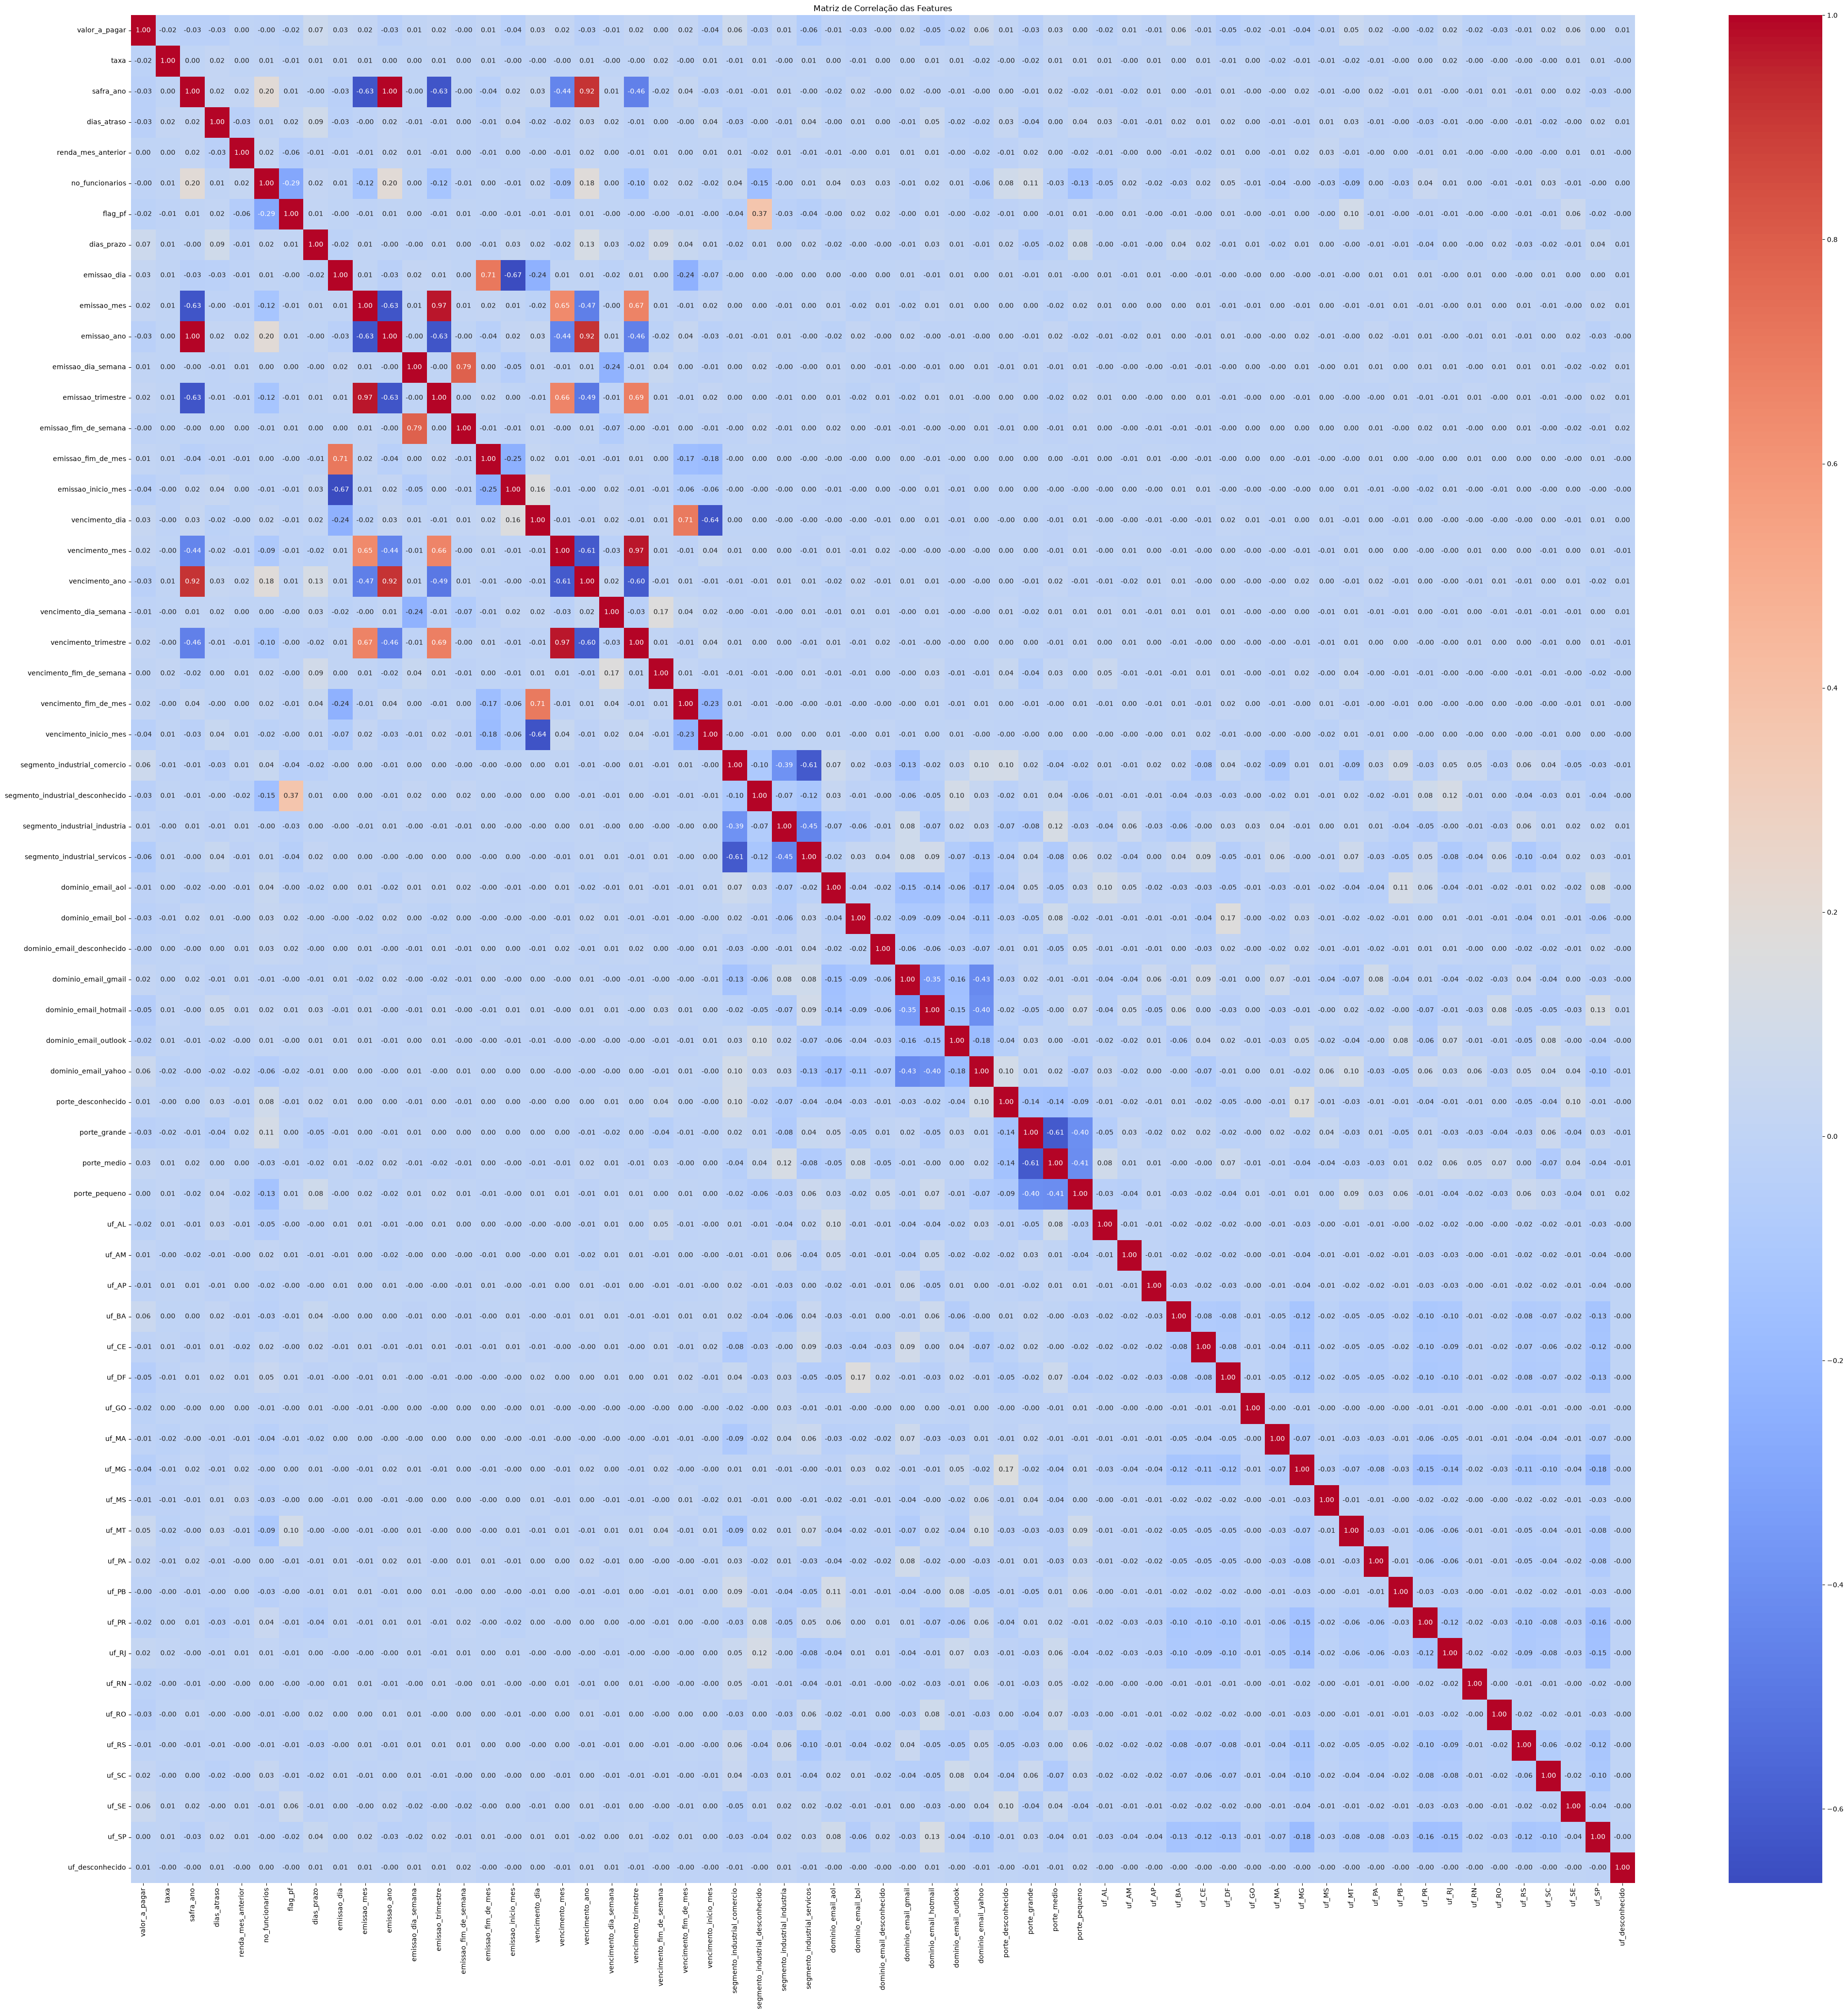

Variáveis para exclusão por correlação >= 0.75:
['emissao_ano', 'emissao_trimestre', 'emissao_fim_de_semana', 'vencimento_ano', 'vencimento_trimestre']


In [82]:
# Análise da reduância das features que afetam o modelo
X_corr, X_colunas_alta_corr = plot_matriz_corr(X_treino, limite_corr=0.75, figsize=(50, 50))

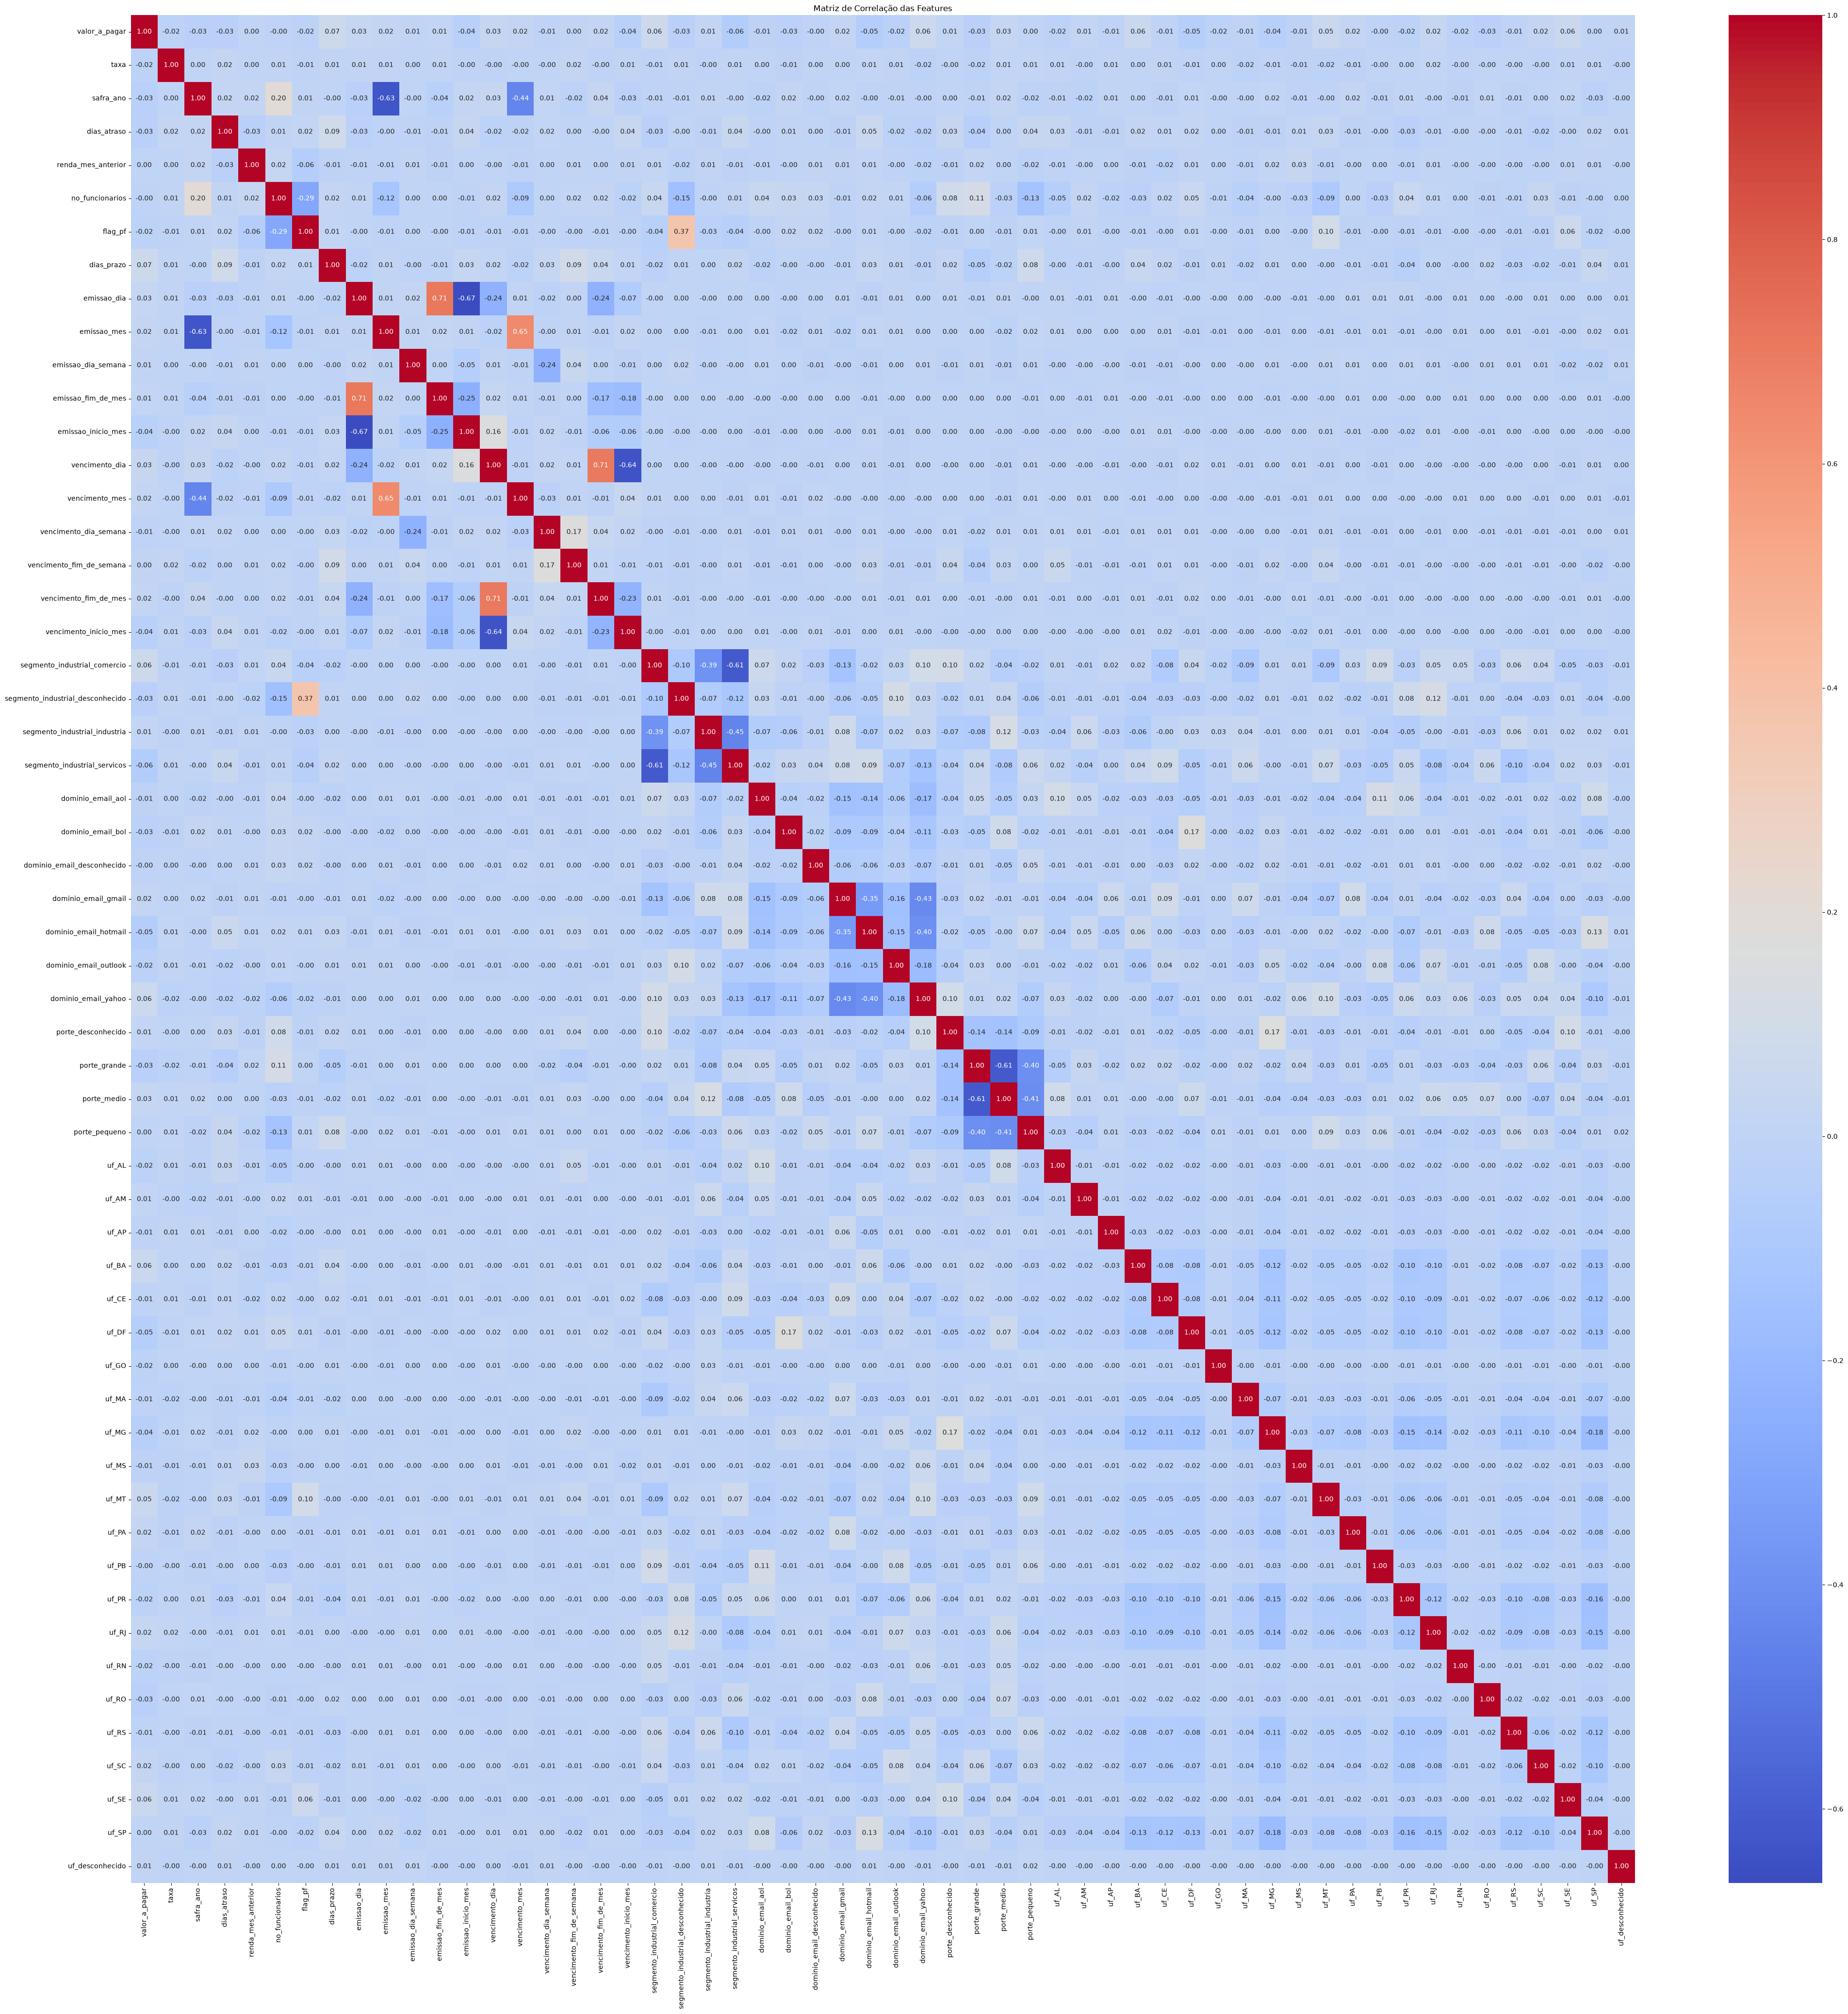

Variáveis para exclusão por correlação >= 0.75:
[]


,valor_a_pagar,taxa,safra_ano,dias_atraso,renda_mes_anterior,no_funcionarios,flag_pf,dias_prazo,emissao_dia,emissao_mes,...,uf_PB,uf_PR,uf_RJ,uf_RN,uf_RO,uf_RS,uf_SC,uf_SE,uf_SP,uf_desconhecido
0,35516.41,6.99,2018,0,236447.0,96.5,0,20,17,8,...,0,0,0,0,0,0,0,0,0,0
1,48811.35,6.99,2018,0,83013.0,139.5,0,39,17,8,...,0,0,0,0,0,0,0,0,0,0
2,55131.20,5.99,2018,0,243615.0,112.0,0,19,17,8,...,0,0,0,0,0,0,0,0,0,0
3,85855.04,6.99,2018,0,294450.0,111.0,0,17,17,8,...,0,0,0,0,0,0,1,0,0,0
4,42072.00,5.99,2018,0,199603.0,108.0,0,17,17,8,...,0,0,0,0,0,0,0,0,0,0


In [83]:
X_treino_limpo = X_treino.drop(columns=X_colunas_alta_corr)
X_treino_limpo_corr, X_limpo_colunas_alta_corr = plot_matriz_corr(X_treino_limpo, figsize=(50,50))
X_treino_limpo.head()

In [84]:
features_treino = X_treino_limpo.columns

## Análise de outliers

In [85]:
print(f"{'Métrica / Feature':<40} | {'qt Outliers':<12} | {'Porcentagem':<12}")
print("-" * 62)

colunas_com_outliers_criticos = []

for col in X_treino_limpo.columns:
    # Ignora colunas que são binárias, pois nelas não existem outliers estatísticos
    if X_treino_limpo[col].nunique() <= 2:
        continue

    Q1 = X_treino_limpo[col].quantile(0.25)
    Q3 = X_treino_limpo[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = X_treino_limpo[
        (X_treino_limpo[col] < limite_inferior) | (X_treino_limpo[col] > limite_superior)
        ]
    total_outliers = len(outliers)
    porcentagem = (total_outliers / len(X_treino_limpo)) * 100

    if porcentagem > 5:
        colunas_com_outliers_criticos.append(col)

        print(f"{col:<40} | {total_outliers:<12} | {porcentagem:.2f}%")

Métrica / Feature                        | qt Outliers  | Porcentagem 
--------------------------------------------------------------
valor_a_pagar                            | 2618         | 5.34%
taxa                                     | 8161         | 16.65%
dias_atraso                              | 6029         | 12.30%
dias_prazo                               | 3873         | 7.90%


In [86]:
df_base_pagamentos_val.isna().sum().loc[lambda x: x > 0]

valor_a_pagar    169
dtype: int64

In [87]:
df_base_info_val = df_base_info[df_base_info['safra_ref'] <= corte_val_fim].copy()

df_val = (
    df_base_pagamentos_val
    .merge(df_base_info_val, on=['id_cliente', 'safra_ref'], how='left')
    )

df_val = (
    df_val
    .merge(df_base_cadast_tratado, on='id_cliente', how='left')
    )

df_val = fillna_com_mediana_cliente(df_val)
df_val = cria_features_temporais(df_val)

Colunas com dados nulos atens do tratamento: ['valor_a_pagar', 'renda_mes_anterior', 'no_funcionarios']
Colunas com dados nulos após tratamento: []


In [88]:
X_val = df_val.drop(
    [
        'id_cliente', 'safra_ref', 'inadimplente',
        'data_emissao_documento', 'data_pagamento',
        'data_vencimento', 'data_cadastro'
    ], axis=1)

X_val = pd.get_dummies(
    X_val,
    X_val.select_dtypes('object').columns,
    drop_first=False,
    dtype=int
)

X_val = X_val[features_treino]

y_val = df_val['inadimplente']

KeyError: "['uf_GO'] not in index"